# 03 - Modelling

Week 2: baselines (Logistic Regression and Decision Tree). Random Forest and XGBoost come next.

- 80/20 split, stratified on `loan_default`, grouped by customer, `random_state=42`
- tuning with 5-fold CV on the train set only (ROC-AUC)
- the test set isn't touched until the final model is picked
- metrics below are out-of-fold on the train set, threshold 0.5

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
from train import run
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

results, fitted, train, test = run()

train 2721 / test 682, default rate 0.234 / 0.235



logistic_regression  {'model__C': 0.01}
[[1471  613]
 [ 220  417]]



decision_tree  {'model__max_depth': 5, 'model__min_samples_leaf': 60}
[[1414  670]
 [ 225  412]]

5-fold CV on train set:
                     accuracy  precision  recall     f1  roc_auc
model                                                           
logistic_regression     0.694      0.405   0.655  0.500     0.74
decision_tree           0.671      0.381   0.647  0.479     0.70


In [3]:
results.round(3)

,accuracy,precision,recall,f1,roc_auc,best_params
model,,,,,,
logistic_regression,0.694,0.405,0.655,0.500,0.74,{'model__C': 0.01}
decision_tree,0.671,0.381,0.647,0.479,0.70,"{'model__max_depth': 5, 'model__min_samples_le..."


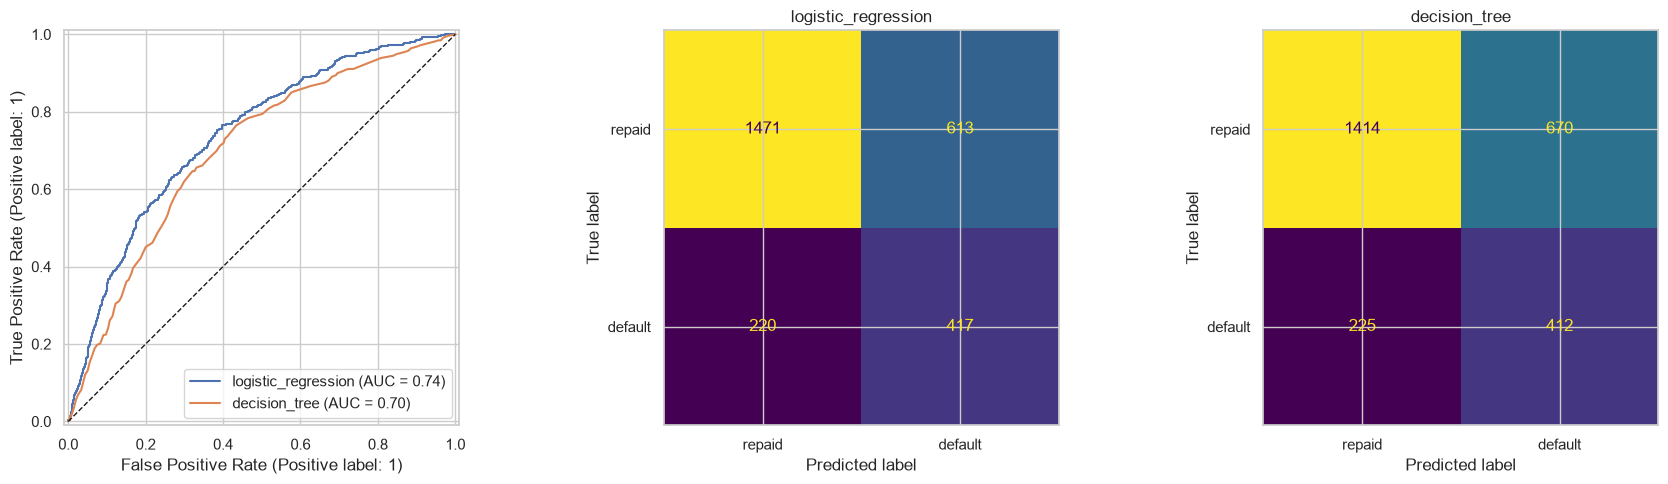

In [4]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from features import NUMERIC, CATEGORICAL, TARGET

X, y, groups = train[NUMERIC + CATEGORICAL], train[TARGET], train["customer_id"]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

oof = {name: cross_val_predict(m, X, y, groups=groups, cv=cv, method="predict_proba")[:, 1]
       for name, m in fitted.items()}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, p in oof.items():
    RocCurveDisplay.from_predictions(y, p, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
for ax, (name, p) in zip(axes[1:], oof.items()):
    ConfusionMatrixDisplay.from_predictions(y, (p >= 0.5).astype(int), ax=ax,
                                            display_labels=["repaid", "default"], colorbar=False)
    ax.set_title(name)
plt.tight_layout()

## What the logistic regression picked up

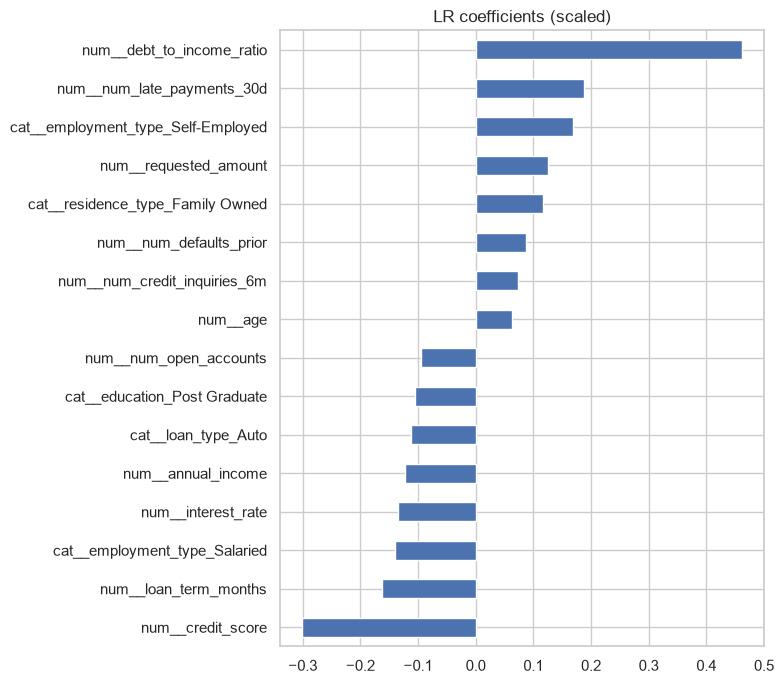

In [5]:
lr = fitted["logistic_regression"]
names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=names).sort_values()
pd.concat([coefs.head(8), coefs.tail(8)]).plot.barh(figsize=(8, 7), title="LR coefficients (scaled)")
plt.tight_layout()

## Baseline notes

- Logistic Regression does better than the tree (ROC-AUC ~0.74 vs ~0.70).
- Recall at 0.5 is ~0.65, a bit under the 0.70 target. Moving the threshold will help
  with that, but ROC-AUC needs to get closer to 0.80, so next up is Random Forest / XGBoost.
- The biggest LR drivers line up with the EDA: debt-to-income, credit score, 30-day late payments, income and
  employment type (self-employed higher risk, salaried lower).